In [9]:
2+

SyntaxError: invalid syntax (4209523232.py, line 1)

In [10]:
2+6

8

In [11]:
!pip install pandas numpy scikit-learn matplotlib seaborn joblib ucimlrepo

In [12]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# Download Steel Plates Faults dataset
steel_data = fetch_ucirepo(id=198)

# Extract features and target
X = steel_data.data.features
y = steel_data.data.targets

# Display feature information
print("Feature dataset shape:", X.shape)

print("\nTarget dataset shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget columns:")
print(y.columns.tolist())

Matplotlib is building the font cache; this may take a moment.


Feature dataset shape: (1941, 27)

Target dataset shape: (1941, 7)

Feature columns:
['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas', 'Minimum_of_Luminosity']

Target columns:
['Pastry', 'Z_Scratch', 'K_Scratch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']


In [13]:
# Convert target columns into a single class label

target_columns = y.columns.tolist()

# Check that each row has exactly one positive class
y_binary = y.apply(pd.to_numeric)

assert (y_binary.sum(axis=1) == 1).all(), (
    "Target data is not one-hot encoded correctly."
)

# Convert one-hot encoded targets into class names
y_final = y_binary.idxmax(axis=1)

# Create final dataset
df = X.copy()
df["Fault_Type"] = y_final

# Display final dataset
print("Final dataset shape:", df.shape)

print("\nFirst five records:")
display(df.head())

print("\nFault types:")
print(df["Fault_Type"].unique())

Final dataset shape: (1941, 28)

First five records:


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,...,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Minimum_of_Luminosity,Fault_Type
0,42,50,270900,270944,267,17,44,24220,108,1687,...,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,76,Pastry
1,645,651,2538079,2538108,108,10,30,11397,123,1687,...,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,84,Pastry
2,829,835,1553913,1553931,71,8,19,7972,125,1623,...,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,99,Pastry
3,853,860,369370,369415,176,13,45,18996,126,1353,...,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,99,Pastry
4,1289,1306,498078,498335,2409,60,260,246930,126,1353,...,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,37,Pastry



Fault types:
['Pastry' 'Z_Scratch' 'K_Scratch' 'Stains' 'Dirtiness' 'Bumps'
 'Other_Faults']


In [14]:
# Check missing values
print("Missing values:")
print(df.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate records:")
print(df.duplicated().sum())

# Check class distribution
print("\nFault type distribution:")
print(df["Fault_Type"].value_counts())

# Check percentage distribution
print("\nClass percentages:")
print(
    df["Fault_Type"].value_counts(normalize=True) * 100
)

Missing values:
0

Duplicate records:
0

Fault type distribution:
Fault_Type
Other_Faults    673
Bumps           402
K_Scratch       391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
Name: count, dtype: int64

Class percentages:
Fault_Type
Other_Faults    34.672849
Bumps           20.710974
K_Scratch       20.144256
Z_Scratch        9.788769
Pastry           8.140134
Stains           3.709428
Dirtiness        2.833591
Name: proportion, dtype: float64


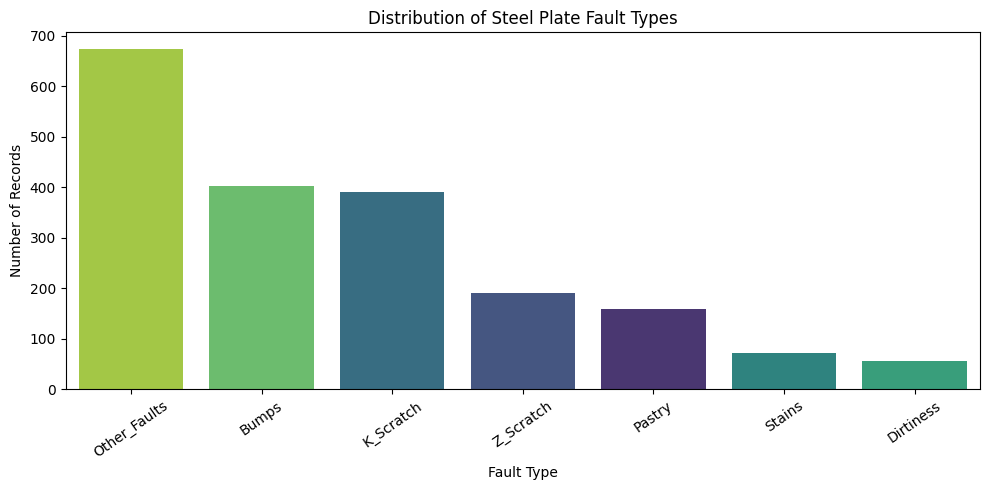

In [15]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Fault_Type",
    order=df["Fault_Type"].value_counts().index,
    hue="Fault_Type",
    legend=False,
    palette="viridis"
)

plt.title("Distribution of Steel Plate Fault Types")
plt.xlabel("Fault Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=35)

plt.tight_layout()
plt.show()

In [16]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=["Fault_Type"])
y = df["Fault_Type"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training dataset:", X_train.shape)
print("Testing dataset:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training dataset: (1552, 27)
Testing dataset: (389, 27)

Training target distribution:
Fault_Type
Other_Faults    538
Bumps           321
K_Scratch       313
Z_Scratch       152
Pastry          126
Stains           58
Dirtiness        44
Name: count, dtype: int64

Testing target distribution:
Fault_Type
Other_Faults    135
Bumps            81
K_Scratch        78
Z_Scratch        38
Pastry           32
Stains           14
Dirtiness        11
Name: count, dtype: int64


In [17]:
import os

# Create data directory
os.makedirs("data", exist_ok=True)

# Combine test features and target
test_data = X_test.copy()

test_data["Fault_Type"] = y_test

# Save CSV file
test_data.to_csv(
    "data/test_data.csv",
    index=False
)

print("Test dataset saved successfully!")

Test dataset saved successfully!


In [18]:
print("========== DATASET SUMMARY ==========")

print("Total records:", df.shape[0])

print("Total input features:", X.shape[1])

print("Number of classes:", y.nunique())

print("Training records:", X_train.shape[0])

print("Testing records:", X_test.shape[0])

print("Missing values:", df.isnull().sum().sum())

print(
    "Test CSV created:",
    os.path.exists("data/test_data.csv")
)

print("\nAll fault classes:")
print(sorted(y.unique()))

========== DATASET SUMMARY ==========
Total records: 1941
Total input features: 27
Number of classes: 7
Training records: 1552
Testing records: 389
Missing values: 0
Test CSV created: True

All fault classes:
['Bumps', 'Dirtiness', 'K_Scratch', 'Other_Faults', 'Pastry', 'Stains', 'Z_Scratch']


In [19]:
# Import preprocessing libraries

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Import model selection
from sklearn.model_selection import train_test_split

# Import classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Import model saving library
import joblib
import os

print("All machine learning libraries imported successfully!")

All machine learning libraries imported successfully!


In [20]:
# Identify numerical columns

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Total numerical features:", len(numeric_features))

print("\nNumerical feature names:")
print(numeric_features)

Total numerical features: 27

Numerical feature names:
['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas', 'Minimum_of_Luminosity']


In [21]:
# Create preprocessing pipeline

numeric_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [22]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Naive Bayes": GaussianNB(),

    "Support Vector Machine": SVC(
        probability=True,
        random_state=42
    )
}

print("Five classification models defined successfully!")

Five classification models defined successfully!


In [23]:
# Dictionary to store trained pipelines
trained_models = {}

# Train all five models
for name, model in models.items():

    print("\nTraining:", name)

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "trained successfully!")

print("\nAll five models trained successfully!")


Training: Logistic Regression
Logistic Regression trained successfully!

Training: Decision Tree
Decision Tree trained successfully!

Training: KNN
KNN trained successfully!

Training: Naive Bayes
Naive Bayes trained successfully!

Training: Support Vector Machine


/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Support Vector Machine trained successfully!

All five models trained successfully!


In [24]:
# Store evaluation results
results = []

for name, model in trained_models.items():

    # Predictions
    y_pred = model.predict(X_test)

    # Probability predictions for AUC
    y_proba = model.predict_proba(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(
        y_test,
        y_proba,
        multi_class="ovr",
        average="weighted",
        labels=model.classes_
    )

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    results.append({
        "ML Model Name": name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "MCC": mcc
    })

    print("\nModel:", name)
    print("Accuracy:", round(accuracy, 4))
    print("AUC:", round(auc, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))
    print("MCC:", round(mcc, 4))


Model: Logistic Regression
Accuracy: 0.7275
AUC: 0.9066
Precision: 0.7329
Recall: 0.7275
F1 Score: 0.7277
MCC: 0.6487

Model: Decision Tree
Accuracy: 0.7429
AUC: 0.8283
Precision: 0.7455
Recall: 0.7429
F1 Score: 0.7429
MCC: 0.6688

Model: KNN
Accuracy: 0.7275
AUC: 0.8941
Precision: 0.7318
Recall: 0.7275
F1 Score: 0.7245
MCC: 0.6548

Model: Naive Bayes
Accuracy: 0.6093
AUC: 0.884
Precision: 0.67
Recall: 0.6093
F1 Score: 0.5883
MCC: 0.5484

Model: Support Vector Machine
Accuracy: 0.7506
AUC: 0.9204
Precision: 0.7578
Recall: 0.7506
F1 Score: 0.7517
MCC: 0.6765


In [25]:
# Convert results into DataFrame
results_df = pd.DataFrame(results)

# Display comparison table
print("MODEL PERFORMANCE COMPARISON")

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "AUC": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "MCC": "{:.4f}"
    })
)

# Save results
os.makedirs("results", exist_ok=True)

results_df.to_csv(
    "results/model_comparison.csv",
    index=False
)

print("Comparison table saved successfully!")

MODEL PERFORMANCE COMPARISON


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.7275,0.9066,0.7329,0.7275,0.7277,0.6487
1,Decision Tree,0.7429,0.8283,0.7455,0.7429,0.7429,0.6688
2,KNN,0.7275,0.8941,0.7318,0.7275,0.7245,0.6548
3,Naive Bayes,0.6093,0.8840,0.6700,0.6093,0.5883,0.5484
4,Support Vector Machine,0.7506,0.9204,0.7578,0.7506,0.7517,0.6765


Comparison table saved successfully!


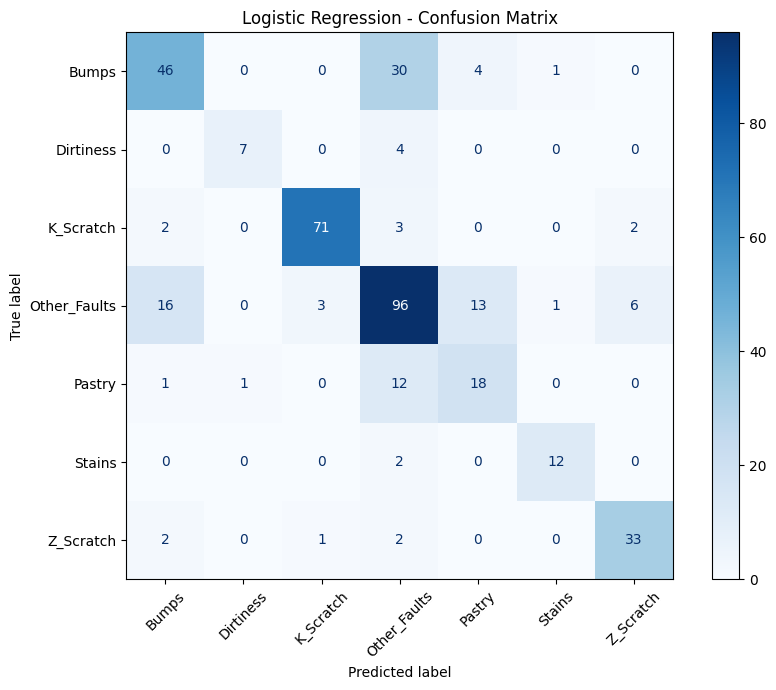

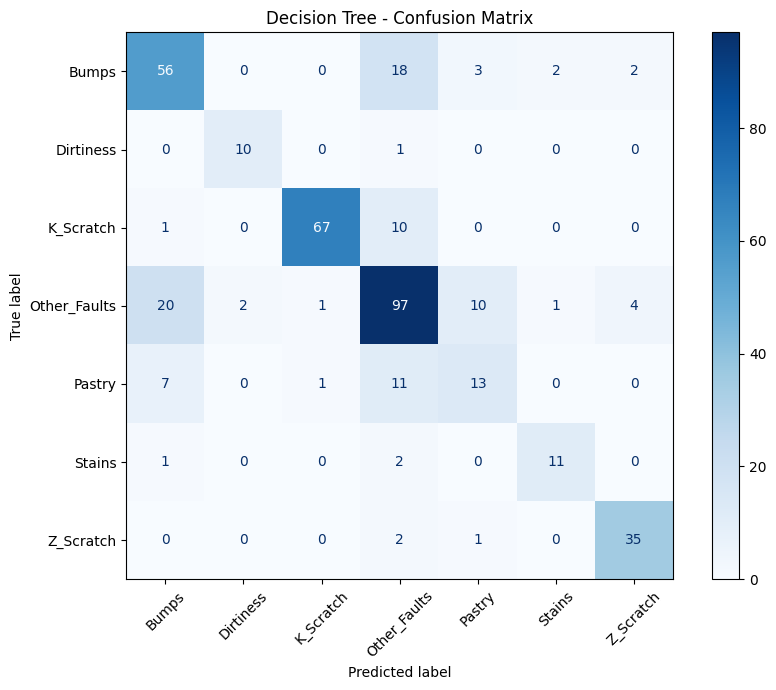

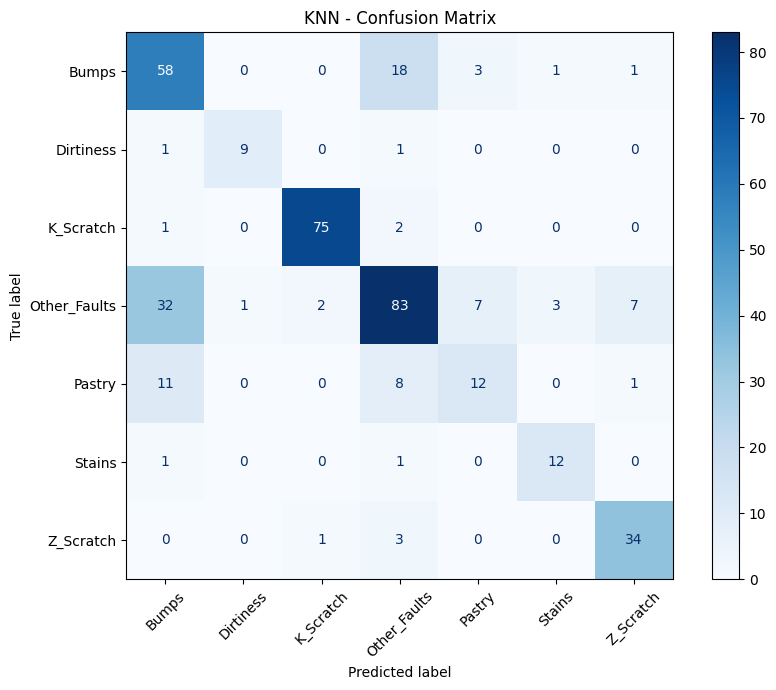

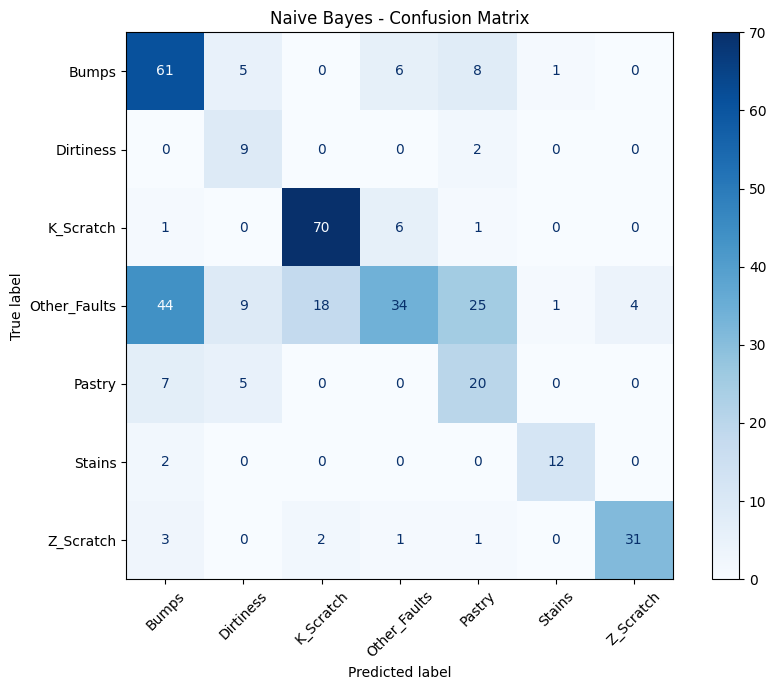

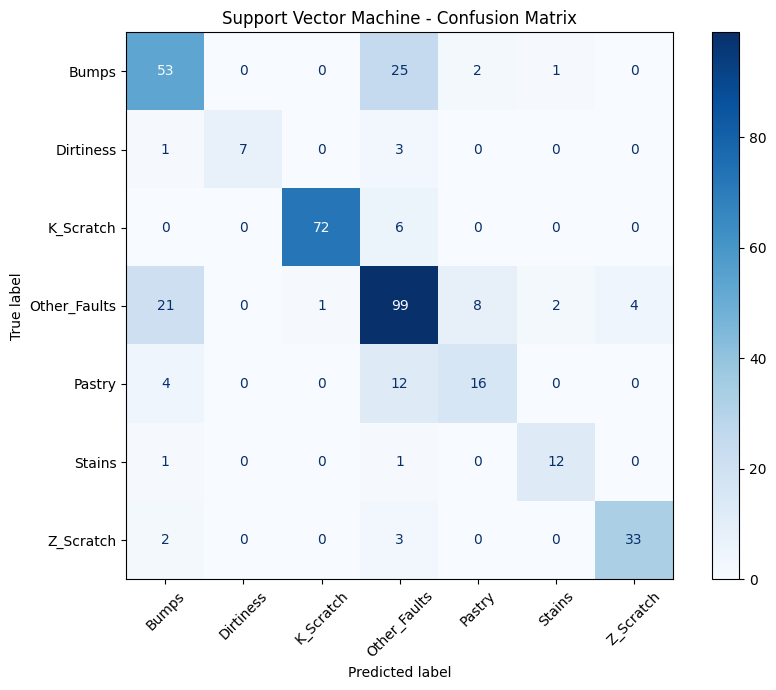

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    fig, ax = plt.subplots(figsize=(9, 7))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=model.classes_,
        xticks_rotation=45,
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name + " - Confusion Matrix")

    plt.tight_layout()
    plt.show()

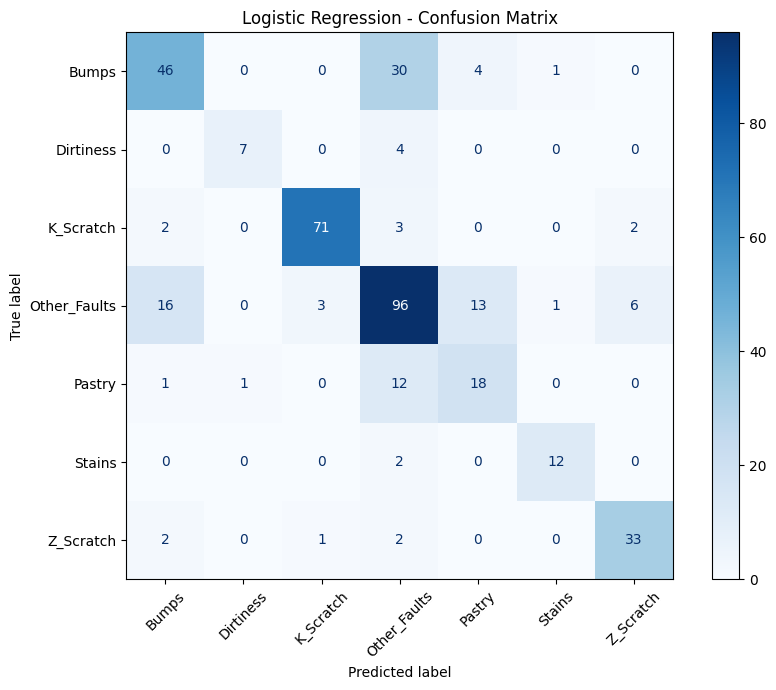

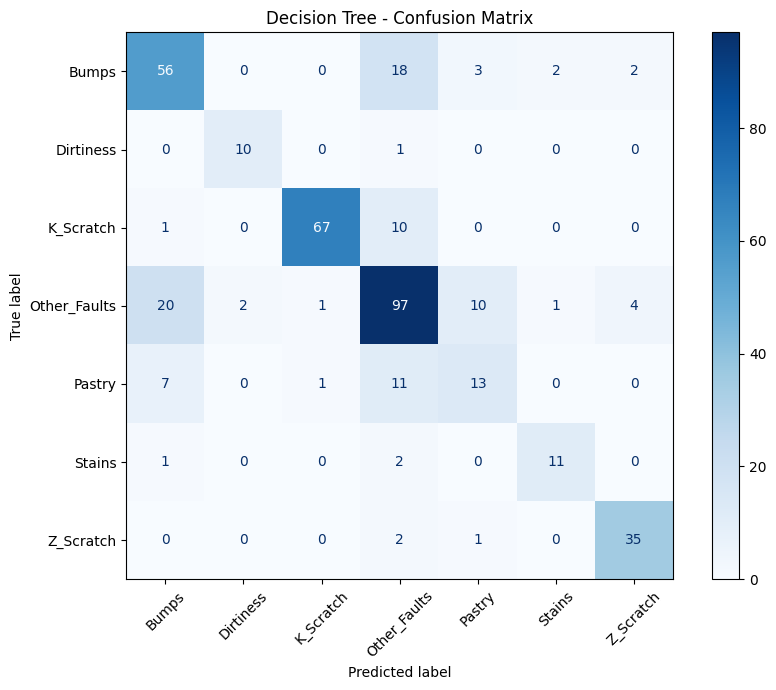

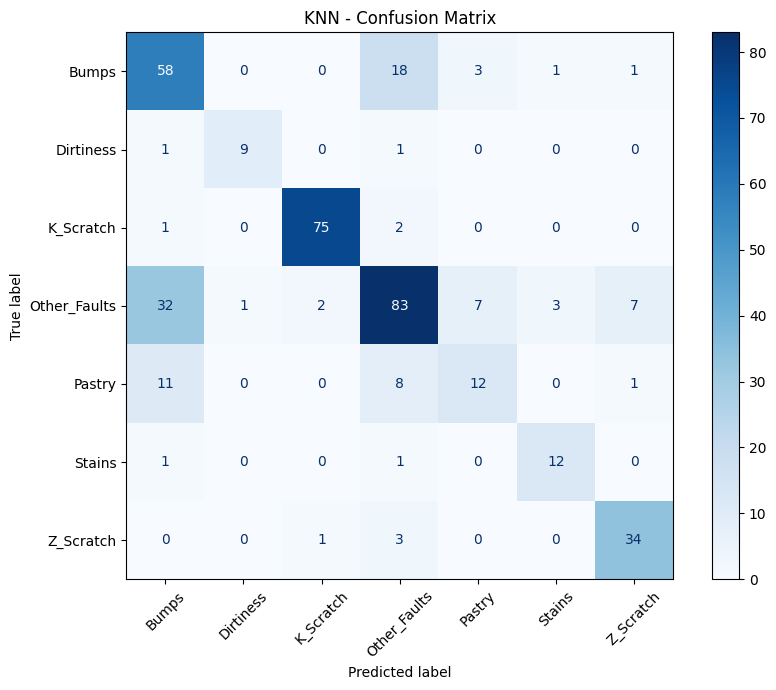

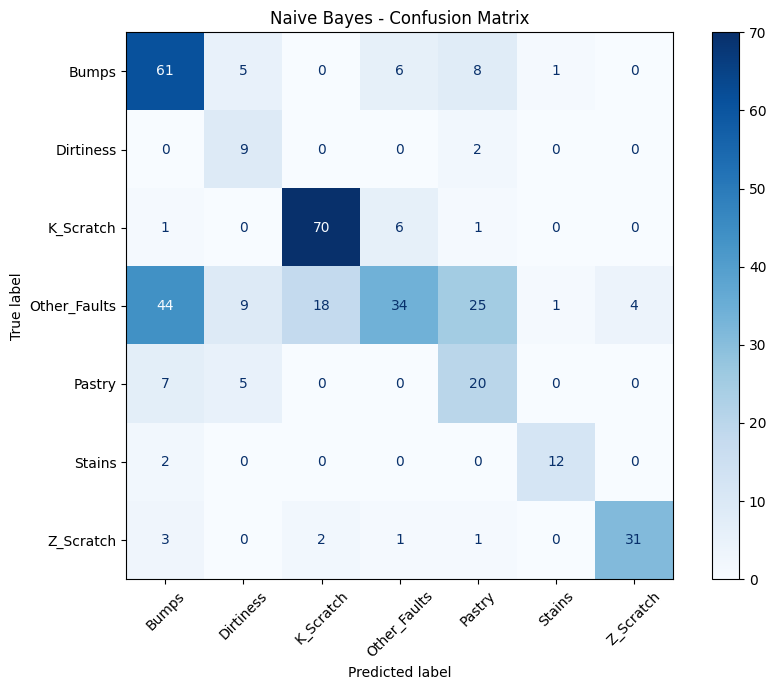

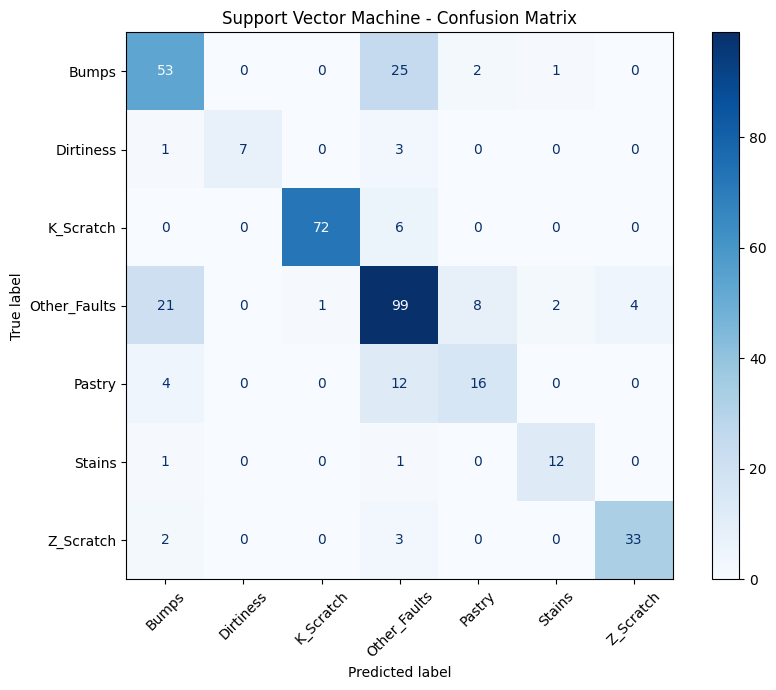

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    fig, ax = plt.subplots(figsize=(9, 7))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=model.classes_,
        xticks_rotation=45,
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name + " - Confusion Matrix")

    plt.tight_layout()
    plt.show()

In [28]:
# Create model directory
os.makedirs("model", exist_ok=True)

# Model filename mapping
model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib"
}

# Save trained models
for name, model in trained_models.items():

    filename = model_files[name]

    joblib.dump(
        model,
        os.path.join("model", filename)
    )

    print(name, "saved successfully!")

print("\nAll five models saved!")

Logistic Regression saved successfully!
Decision Tree saved successfully!
KNN saved successfully!
Naive Bayes saved successfully!
Support Vector Machine saved successfully!

All five models saved!


In [29]:
print("Saved model files:")

for filename in os.listdir("model"):
    print(filename)

print("\nSaved comparison results:")
print(os.listdir("results"))

print("\nTest dataset:")
print(os.path.exists("data/test_data.csv"))

Saved model files:
svm.joblib
naive_bayes.joblib
logistic_regression.joblib
decision_tree.joblib
knn.joblib

Saved comparison results:
['model_comparison.csv']

Test dataset:
True


In [31]:
Steel_Plate_Fault_Classification/
│
├── data/
│   └── test_data.csv
│
├── model/
│   ├── logistic_regression.joblib
│   ├── decision_tree.joblib
│   ├── knn.joblib
│   ├── naive_bayes.joblib
│   └── svm.joblib
│
├── results/
│   └── model_comparison.csv
│
├── screenshots/
│
└── Steel_Plate_Fault_Classification.ipynb

SyntaxError: invalid character '│' (U+2502) (392631382.py, line 2)

In [32]:
import os

# Create project folders
folders = [
    "data",
    "model",
    "results",
    "screenshots"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [33]:
for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints"]]
    level = root.count(os.sep)

    print("    " * level + os.path.basename(root) + "/")

    for file in files:
        if file.endswith((".csv", ".joblib", ".ipynb")):
            print("    " * (level + 1) + file)

./
    test.ipynb
    results/
        model_comparison.csv
    data/
        test_data.csv
    screenshots/
    model/
        svm.joblib
        naive_bayes.joblib
        logistic_regression.joblib
        decision_tree.joblib
        knn.joblib


In [34]:
import joblib

joblib.dump(
    trained_models["Logistic Regression"],
    "model/logistic_regression.joblib"
)

joblib.dump(
    trained_models["Decision Tree"],
    "model/decision_tree.joblib"
)

joblib.dump(
    trained_models["KNN"],
    "model/knn.joblib"
)

joblib.dump(
    trained_models["Naive Bayes"],
    "model/naive_bayes.joblib"
)

joblib.dump(
    trained_models["Support Vector Machine"],
    "model/svm.joblib"
)

print("All models saved successfully!")

All models saved successfully!


In [35]:
results_df.to_csv(
    "results/model_comparison.csv",
    index=False
)

print("Comparison table saved!")

Comparison table saved!


In [36]:
required_files = [
    "data/test_data.csv",
    "model/logistic_regression.joblib",
    "model/decision_tree.joblib",
    "model/knn.joblib",
    "model/naive_bayes.joblib",
    "model/svm.joblib",
    "results/model_comparison.csv"
]

for file in required_files:
    print(file, ":", os.path.exists(file))

data/test_data.csv : True
model/logistic_regression.joblib : True
model/decision_tree.joblib : True
model/knn.joblib : True
model/naive_bayes.joblib : True
model/svm.joblib : True
results/model_comparison.csv : True
